# Задание 7. Обучение первой ML-модели (baseline)

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Полный цикл «обучение → оценка → сохранение → загрузка → предсказание» для базовой модели:
**Logistic Regression** (`class_weight='balanced'`, `max_iter=1000`) в одном Pipeline с векторизатором
из задания 6. Модель обучается на train, все метрики считаются на **validation**. Тестовая выборка
в этом задании не используется — она понадобится один раз для итоговой модели (задание 8).

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)

from ml.features import RANDOM_STATE, build_vectorizer, load_split  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
ARTIFACTS = PROJECT_ROOT / "ml" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "sms_clean.csv", keep_default_na=False)
parts = load_split(df)  # индексы из data/processed/sms_split.json (задание 6)
train, val = parts["train"], parts["val"]
X_cols = ["text_raw", "text_clean"]
print(f"train: {len(train)}, validation: {len(val)}")

train: 3594, validation: 770


## 1. Pipeline и обучение на обучающей выборке

In [2]:
baseline = Pipeline([
    ("features", build_vectorizer()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])

start = time.perf_counter()
baseline.fit(train[X_cols], train["label"])
train_seconds = time.perf_counter() - start
print(f"Время обучения: {train_seconds:.2f} с")
print("Признаков:", len(baseline.named_steps["features"].get_feature_names_out()))

Время обучения: 0.71 с
Признаков: 33494


## 2. Предсказания и вероятности на валидационной выборке

`predict_proba` возвращает вероятность каждого класса; второй столбец — вероятность
«мошенничества» $P_{sms}$. Порог классификации в baseline — 0,5 (подбор порога — задание 8).

In [3]:
THRESHOLD = 0.5
y_val = val["label"].to_numpy()
proba_val = baseline.predict_proba(val[X_cols])[:, 1]
pred_val = (proba_val >= THRESHOLD).astype(int)
assert (pred_val == baseline.predict(val[X_cols])).all()

val_view = val.assign(proba=proba_val.round(4), pred=pred_val)[["id", "text_raw", "label", "pred", "proba"]]
val_view.head(8)

,id,text_raw,label,pred,proba
0,5,"Nah I don't think he goes to usf, he lives around here though",0,0,0.0237
1,17,Oh k...i'm watching here:),0,0,0.0084
2,25,Ffffffffff. Alright no way I can meet up with you sooner?,0,0,0.0296
3,45,Great! I hope you like your man well endowed. I am &lt;#&gt; inches...,0,0,0.0657
4,49,"Yeah hopefully, if tyler can't do it I could maybe ask around a bit",0,0,0.0168
5,51,What you thinked about me. First time you saw me in class.,0,0,0.0251
6,53,K fyi x has a ride early tomorrow morning but he's crashing at our place tonight,0,0,0.0184
7,70,I plane to give on this month end.,0,0,0.0501


## 3. Метрики на валидационной выборке

In [4]:
metrics = {
    "Accuracy": accuracy_score(y_val, pred_val),
    "Precision (мошенничество)": precision_score(y_val, pred_val),
    "Recall (мошенничество)": recall_score(y_val, pred_val),
    "F1 (мошенничество)": f1_score(y_val, pred_val),
    "F1 (macro)": f1_score(y_val, pred_val, average="macro"),
    "ROC-AUC": roc_auc_score(y_val, proba_val),
    "PR-AUC": average_precision_score(y_val, proba_val),
}
# время предсказания одного SMS: 200 вызовов по одному сообщению
sample = val[X_cols].head(200)
start = time.perf_counter()
for i in range(len(sample)):
    baseline.predict_proba(sample.iloc[[i]])
ms_per_sms = (time.perf_counter() - start) / len(sample) * 1000

metrics_table = pd.Series(metrics).round(4).to_frame("Validation")
print(f"Время предсказания одного SMS: {ms_per_sms:.2f} мс")
metrics_table

Время предсказания одного SMS: 4.03 мс


,Validation
Accuracy,0.9844
Precision (мошенничество),0.9655
Recall (мошенничество),0.9032
F1 (мошенничество),0.9333
F1 (macro),0.9623
ROC-AUC,0.9939
PR-AUC,0.9796


In [5]:
print(classification_report(y_val, pred_val, target_names=["ham (0)", "spam (1)"], digits=4))

              precision    recall  f1-score   support

     ham (0)     0.9868    0.9956    0.9912       677
    spam (1)     0.9655    0.9032    0.9333        93

    accuracy                         0.9844       770
   macro avg     0.9762    0.9494    0.9623       770
weighted avg     0.9842    0.9844    0.9842       770



Требования ТЗ к итоговой SMS-модели (раздел 3.4): Recall ≥ 0,90, Precision ≥ 0,90, F1 ≥ 0,90 —
здесь это ориентир: baseline оценивается на validation, финальная проверка на test — в задании 8.

TN = 674, FP = 3, FN = 9, TP = 84


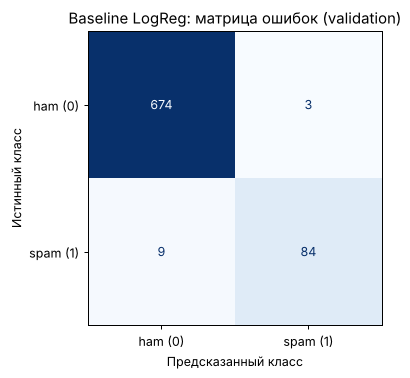

In [6]:
cm = confusion_matrix(y_val, pred_val)
fig, ax = plt.subplots(figsize=(5, 4.3))
ConfusionMatrixDisplay(cm, display_labels=["ham (0)", "spam (1)"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Baseline LogReg: матрица ошибок (validation)")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_confusion_matrix_baseline.png", dpi=150)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

## 4. Разбор ошибок: 5 FN и 5 FP

**FN (False Negative)** — мошенническое SMS, которое модель пропустила (опаснее всего).
**FP (False Positive)** — безопасное SMS, ошибочно отмеченное как мошенничество.

In [7]:
errors = val.assign(proba=proba_val.round(3), pred=pred_val)
fn_df = errors[(errors["label"] == 1) & (errors["pred"] == 0)].sort_values("proba")
fp_df = errors[(errors["label"] == 0) & (errors["pred"] == 1)].sort_values("proba", ascending=False)
print(f"Всего FN: {len(fn_df)}, FP: {len(fp_df)}")
print("\nFN — пропущенные мошеннические (P_sms по возрастанию):")
fn_df[["id", "proba", "text_raw"]].head(5)

Всего FN: 9, FP: 3

FN — пропущенные мошеннические (P_sms по возрастанию):


,id,proba,text_raw
383,2775,0.041,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to stay out all night?
202,1431,0.067,For sale - arsenal dartboard. Good condition but no doubles or trebles!
744,5373,0.126,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?
675,4950,0.245,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties..."
382,2771,0.267,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...


In [8]:
print("FP — ложные тревоги (P_sms по убыванию):")
near_fp = errors[(errors["label"] == 0) & (errors["pred"] == 0)].sort_values("proba", ascending=False).head(5 - len(fp_df.head(5)))
print(f"FP на validation всего {len(fp_df)}; для пяти примеров добавлены «почти ошибки» — ham с наибольшей P_sms ниже порога:")
pd.concat([fp_df.head(5).assign(тип="FP"), near_fp.assign(тип="почти FP")])[["id", "тип", "proba", "text_raw"]]

FP — ложные тревоги (P_sms по убыванию):
FP на validation всего 3; для пяти примеров добавлены «почти ошибки» — ham с наибольшей P_sms ниже порога:


,id,тип,proba,text_raw
510,3739,FP,0.609,"Plz note: if anyone calling from a mobile Co. &amp; asks u to type # &lt;#&gt; or # &lt;#&gt; . Do not do so. Disconnect the call,coz i..."
311,2280,FP,0.599,Hmm...Bad news...Hype park plaza $700 studio taken...Only left 2 bedrm-$900...
28,181,FP,0.508,Hi! You just spoke to MANEESHA V. We'd like to know if you were satisfied with the experience. Reply Toll Free with Yes or No.
527,3850,почти FP,0.429,Can you plz tell me the ans. BSLVYL sent via fullonsms.com
329,2409,почти FP,0.380,"Solve d Case : A Man Was Found Murdered On &lt;DECIMAL&gt; . &lt;#&gt; AfterNoon. 1,His wife called Police. 2,Police questioned everyo..."


**Комментарии к ошибкам.**

*Пропущенные мошеннические SMS (FN, всего 9 из 93 = 9,7%):*

| id | $P_{sms}$ | Почему модель ошиблась |
| --: | --: | :--- |
| 2775 | 0,041 | Загадка из платной подписки, написанная как обычный вопрос. Нет телефона, суммы, ссылки и призыва к действию; по одному тексту её не отличить от личного сообщения (пограничная разметка). |
| 1431 | 0,067 | Частное объявление «For sale — dartboard» без контакта и цены. Лексика нейтральная, сильных признаков (`<phone>`, `<money>`) нет. |
| 5373 | 0,126 | Реклама сервиса знакомств, замаскированная под личное сообщение: первое лицо, вопрос к собеседнику, разговорный стиль. |
| 4950 | 0,245 | Есть слово free, но нет номера, ссылки и суммы; вежливое обращение «Hi this is Amy» снижает вероятность. |
| 2771 | 0,267 | Промо-акция Burger King: слово winner есть, но названия брендов и спортивная лексика в обучающем спаме почти не встречались. |

Общая причина: все пропуски не содержат `<phone>`, `<money>` и `<url>` — самых сильных признаков спама
(в EDA таких spam-сообщений было 16,8%). Модель на них опирается сильно, и спам без контактов «проседает» ниже порога 0,5.
При этом ROC-AUC = 0,994: по вероятности такие сообщения всё же ранжируются выше большинства ham, поэтому снижение
порога (задание 8) может поднять Recall ценой небольшого числа ложных тревог.

*Ложные тревоги (FP).* На validation их всего **3** (из 677 ham — 0,44%), поэтому ниже разобраны все три, а для пяти
примеров добавлены два безопасных SMS с наибольшей вероятностью ниже порога («почти ошибки»):

| id | $P_{sms}$ | Ошибка? | Почему модель ошиблась |
| --: | --: | :-: | :--- |
| 3739 | 0,609 | FP | Предупреждение **о** мошенничестве: «mobile», «type #», «sim card», «verified», «confirmd». Лексика мошеннической схемы та же, смысл — противоположный. |
| 2280 | 0,599 | FP | Две суммы в долларах ($700, $900) → токен `<money>`, который встречается лишь в 0,3% ham. |
| 181 | 0,508 | FP | Опрос о качестве обслуживания: «Reply … Toll Free with Yes or No» — типичный призыв к ответу и слово free, как в спаме. |
| 3850 | 0,429 | нет | Подпись SMS-шлюза «sent via fullonsms.com» превращается в `<url>`. |
| 2409 | 0,380 | нет | Длинная «цепочка»-загадка с нумерацией и призывом «Reply With Reason» — стиль массовой рассылки. |

Общая причина: легитимные сообщения с суммами, ссылками и призывом «reply / free». Такие ошибки уменьшаются
порогом, учитывающим Precision, и объяснением результата (пользователь видит, какие признаки сработали).

## 5. Сохранение Pipeline и проверка загрузки

Сохраняется весь Pipeline: векторизатор (словари TF-IDF, IDF-веса, масштабирование) и классификатор.

In [9]:
import sklearn  # noqa: E402

model_path = ARTIFACTS / "sms_baseline.joblib"
meta_path = ARTIFACTS / "sms_baseline_meta.json"
joblib.dump(baseline, model_path)
meta = {
    "model": "sms_baseline",
    "version": "0.1.0",
    "algorithm": "LogisticRegression(class_weight='balanced', max_iter=1000)",
    "features": "TF-IDF words (1,2) + TF-IDF char_wb (3,5) + 8 manual features",
    "n_features": int(len(baseline.named_steps["features"].get_feature_names_out())),
    "threshold": THRESHOLD,
    "trained_on": f"train ({len(train)} SMS), data/processed/sms_split.json",
    "metrics_split": f"validation ({len(val)} SMS)",
    "metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "train_seconds": round(train_seconds, 2),
    "predict_ms_per_sms": round(ms_per_sms, 2),
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "sklearn": sklearn.__version__,
}
meta_path.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Сохранено: {model_path.relative_to(PROJECT_ROOT)} ({model_path.stat().st_size / 1024:.0f} КБ)")
print(f"Метаданные: {meta_path.relative_to(PROJECT_ROOT)}")

Сохранено: ml/artifacts/sms_baseline.joblib (890 КБ)
Метаданные: ml/artifacts/sms_baseline_meta.json


In [10]:
# Отдельная ячейка: загружаем модель из файла и сравниваем предсказания
loaded = joblib.load(model_path)
proba_loaded = loaded.predict_proba(val[X_cols])[:, 1]
print("Предсказания совпадают:", bool((loaded.predict(val[X_cols]) == pred_val).all()))
print("Максимальная разница вероятностей:", float(np.abs(proba_loaded - proba_val).max()))
assert np.allclose(proba_loaded, proba_val)

Предсказания совпадают: True
Максимальная разница вероятностей: 0.0


## 6. Функция `predict_sms(text) -> dict`

Реализована в `ml/predictor.py`: загружает сохранённый Pipeline, нормализует текст той же функцией
`normalize_sms` (через `make_input`) и возвращает метку и вероятность мошенничества.

In [11]:
from ml.predictor import predict_sms  # noqa: E402

manual_texts = [
    "URGENT! Your mobile number has won a £2000 prize. Call 09061701461 to claim now!",
    "Hey, are we still meeting at the library at 6?",
    "Your account has been suspended. Verify your card details at http://secure-bank-verify.example/login",
    "Free entry! Txt WIN to 87121 for a chance to win cash",
    "Can you send me the notes from today's lecture?",
    "Ваша карта заблокирована! Срочно подтвердите данные по ссылке: http://secure-bank-verify.example/login",
    "Привет! Встречаемся завтра в 18:00 у входа.",
]
pd.DataFrame([{"Текст": t, **predict_sms(t, model=loaded)} for t in manual_texts])

,Текст,label,label_id,probability
0,URGENT! Your mobile number has won a £2000 prize. Call 09061701461 to claim now!,fraud,1,0.9999
1,"Hey, are we still meeting at the library at 6?",safe,0,0.0229
2,Your account has been suspended. Verify your card details at http://secure-bank-verify.example/login,fraud,1,0.9308
3,Free entry! Txt WIN to 87121 for a chance to win cash,fraud,1,0.9337
4,Can you send me the notes from today's lecture?,safe,0,0.0477
5,Ваша карта заблокирована! Срочно подтвердите данные по ссылке: http://secure-bank-verify.example/login,fraud,1,0.9845
6,Привет! Встречаемся завтра в 18:00 у входа.,safe,0,0.4548


## 7. Выводы

1. Baseline Logistic Regression на validation: Precision (мошенничество) 0,966, Recall 0,903, F1 0,933, ROC-AUC 0,994,
   PR-AUC 0,980; ошибок 12 из 770 (9 FN, 3 FP). Recall и F1 уже на уровне ориентира ТЗ (≥ 0,90), но это
   validation, а не test.
2. Главный тип ошибок — пропуск спама без телефона, суммы и ссылки. Резерв улучшения — подбор порога и
   сравнение алгоритмов (задание 8).
3. Модель сохранена вместе с векторизатором (`ml/artifacts/sms_baseline.joblib`, около 0,9 МБ), загружается из
   файла и даёт те же вероятности. Время предсказания одного SMS — несколько миллисекунд, что укладывается
   в требование НФТ-1 (≤ 500 мс на весь анализ).
4. Функция `predict_sms(text)` работает на новом тексте, введённом вручную. На русских примерах модель,
   обученная только на английском, ведёт себя ненадёжно: мошенническое SMS распознано в основном по ссылке
   и ручным признакам, а безопасное «Привет! Встречаемся завтра в 18:00» получило вероятность, близкую к
   порогу. Поэтому для `ru` и `kk` ML-оценка текста пока помечается как ненадёжная; проверка на
   собственном наборе — в задании 8.